MD# 01 · Scope and target

**Northvale Credit is a fictional lender; the data is public Lending Club loans.**

Question: which loans can be used to measure default without bias, and is the default rate really climbing?

The target is final: default = `Charged Off` or `Default`, good = `Fully Paid`. A loan still running at the data snapshot has no final outcome, so the scope must contain vintages that have had time to finish. All numbers come from `src/northvale/scope.py` and `reports/metrics.json` (`make analysis`).

In [1]:
import json
import warnings

import pandas as pd
from IPython.display import Image, display

from northvale import config as C

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.max_columns", 20)
m = json.loads(C.METRICS.read_text())


def fig(name, width=900):
    display(Image(filename=str(C.FIGURES / f"{name}.png"), width=width))

MD## 1. Censoring: how many loans are still running at the snapshot?

Share of loans not yet Fully Paid or Charged Off, by issue year and term, over the whole 2.2M-loan file (read with DuckDB, three columns only).

In [2]:
from northvale import scope

cens = scope.censoring_table()
cens.pivot(index="issue_year", columns="term", values="non_terminal_share").loc[2010:2018].style.format("{:.2%}")

term,36 months,60 months
issue_year,,
2010,0.00%,0.00%
2011,0.00%,0.00%
2012,0.00%,0.00%
2013,0.00%,0.03%
2014,0.00%,17.15%
2015,0.05%,32.92%
2016,28.17%,45.23%
2017,59.88%,66.90%
2018,88.03%,90.01%


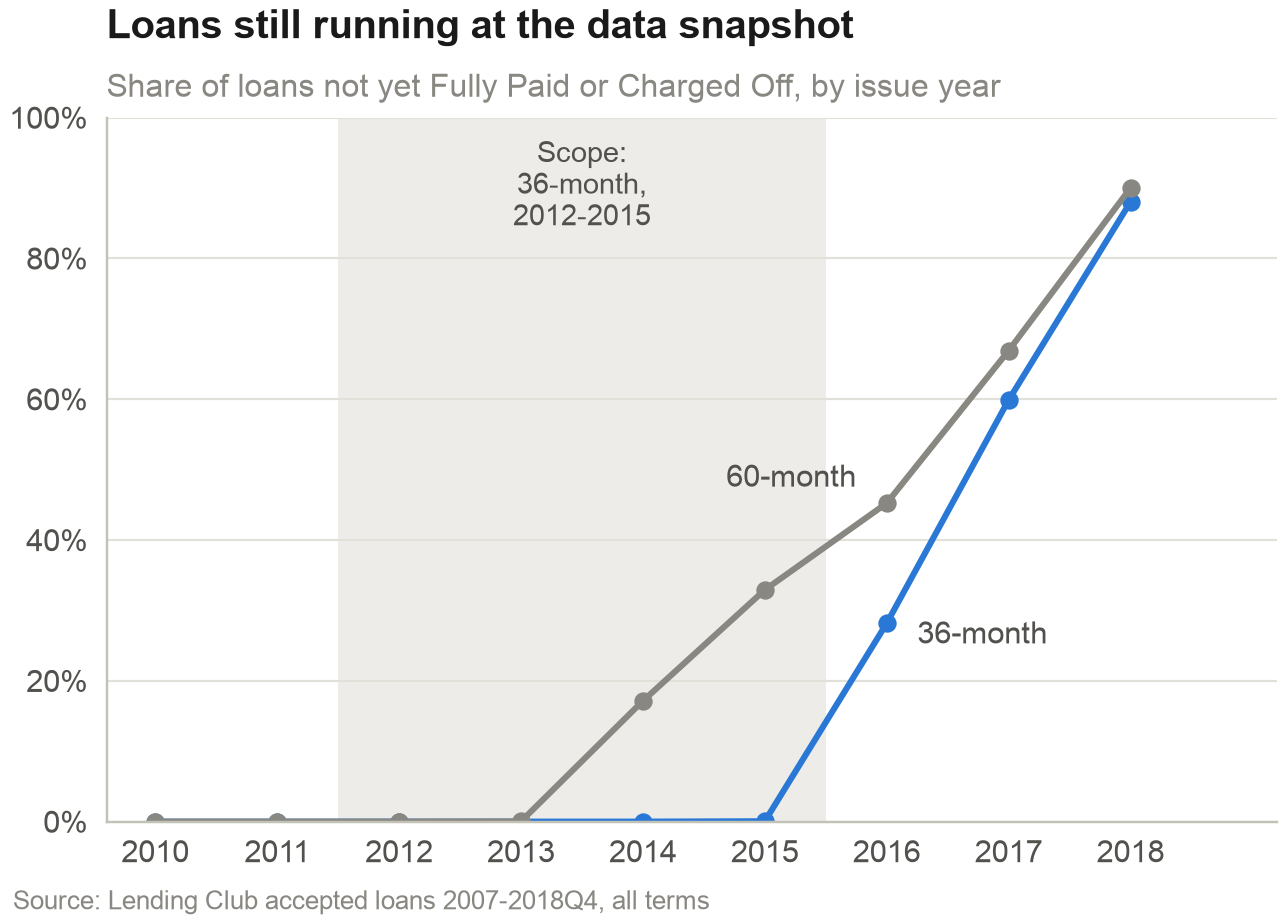

In [3]:
fig("censoring_by_vintage", 650)

MD36-month loans issued up to 2015 are almost all resolved; 2016 onwards and every 60-month vintage after 2013 are not. Scope: **36-month loans issued January 2012 to December 2015.**

## 2. From the raw file to the modelling sample

In [4]:
flow = scope.scope_flow().set_index("issue_year")
flow.index = flow.index.astype(str)
flow.loc["all years"] = flow.sum()
flow

,scope_36m,joint_excluded,non_terminal_excluded,sample
issue_year,,,,
2012,43470,0,0,43470
2013,100422,0,0,100422
2014,162570,0,0,162570
2015,283173,239,147,282787
all years,589635,239,147,589249


MD## 3. Out-of-time split

In [5]:
pd.DataFrame(m["data"]["splits"]).T[["start", "end", "n", "default_rate", "amount"]]

,start,end,n,default_rate,amount
train,2012-01,2014-12,306462,0.1325,"3,825,931,350.0000"
valid,2015-01,2015-06,120790,0.1512,"1,544,467,875.0000"
test,2015-07,2015-12,161997,0.1470,"2,076,167,800.0000"


MD## 4. Is the default rate climbing?

In [6]:
scope.vintage_table("year")[["period", "n_loans", "default_rate", "avg_rate"]]

,period,n_loans,default_rate,avg_rate
0,2012,43470,0.1358,0.1263
1,2013,100422,0.1233,0.1337
2,2014,162570,0.1373,0.1247
3,2015,282787,0.1488,0.1127


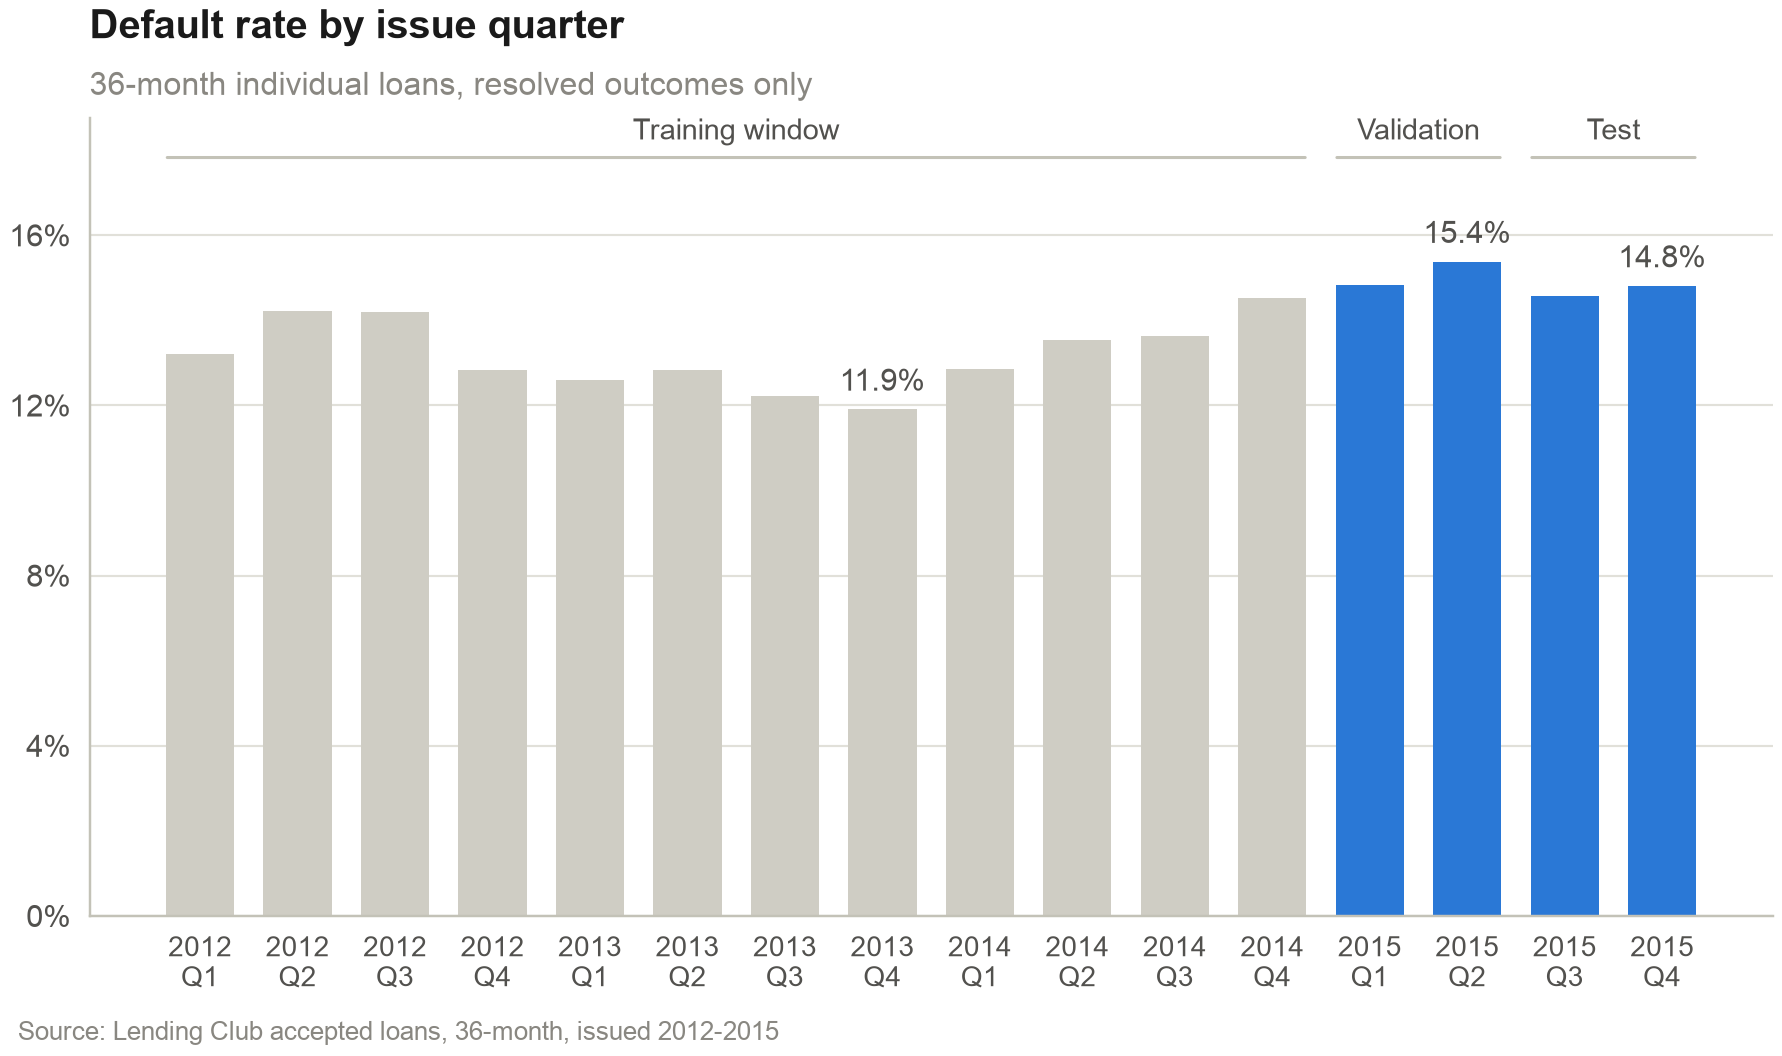

In [7]:
fig("default_rate_by_quarter")

MD The rate fell from 2012 to a low in late 2013, then climbed through 2015. The brief's premise ("default rate climbing") holds from 2013 onwards.

## 5. Riskier mix or riskier loans within each grade?

The change between the 2013 and 2015 vintages splits exactly into a mix effect (new grade mix at old grade default rates) and a rate effect (change in each grade's default rate at the new mix).

In [8]:
dec = scope.mix_vs_rate(scope.grade_year_table(), 2013, 2015)
pd.Series(dec).to_frame("value")

,value
year_from,"2,013.0000"
year_to,"2,015.0000"
default_rate_from,0.1233
default_rate_to,0.1488
change,0.0256
mix_effect,-0.0056
rate_effect,0.0311
share_ab_from,0.5713
share_ab_to,0.5720


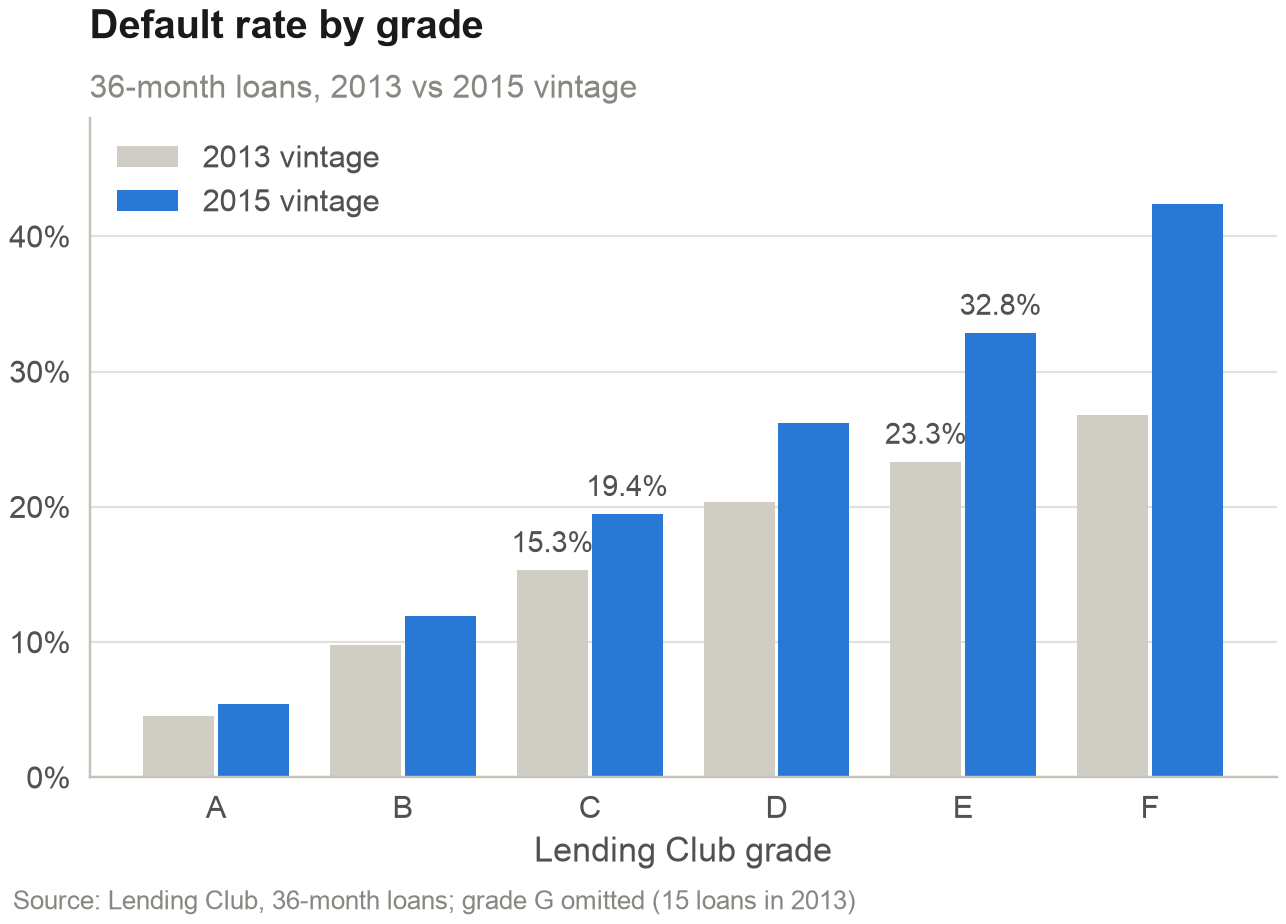

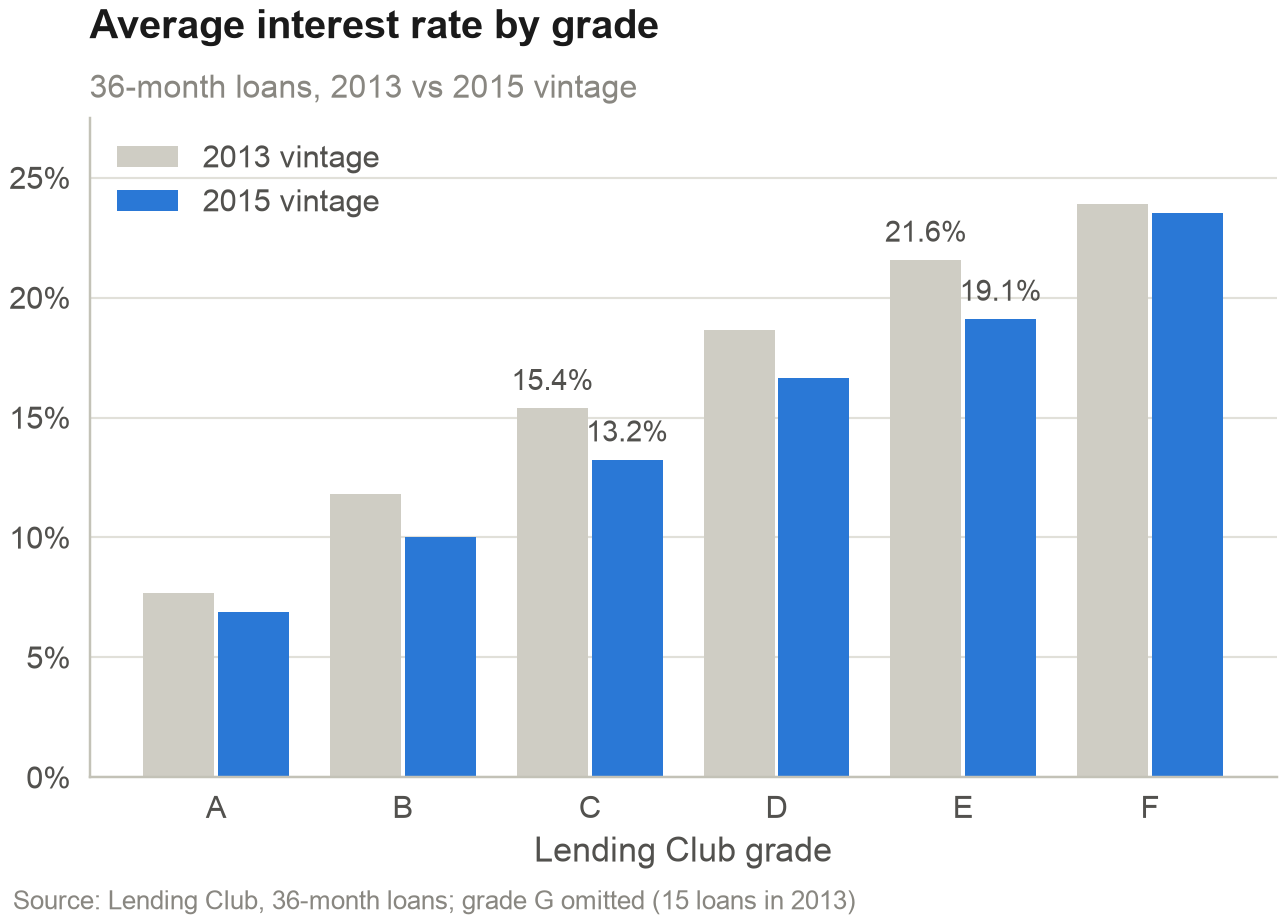

In [9]:
fig("grade_drift_default", 600)
fig("grade_drift_price", 600)

MD**Answer.** The grade mix moved slightly toward safer grades; the whole rise comes from loans inside each grade defaulting more, while each grade's average interest rate fell. A grade-based approval rule written in 2013 approves more risk for less return in 2015. This is a descriptive comparison of vintages, not a causal estimate.